<h1>Monstro da Semana 9: Mímico</h1>

<h3><i>- Bruno Bini Camargo</i></h3>

<h2>Introdução</h2>

O Teorema do Limite Central ($\text{TLC}$) é um dos pilares da teoria da probabilidade e da estatística, estabelecendo que a distribuição da média amostral (ou da soma) de variáveis aleatórias independentes aproxima-se de uma distribuição normal à medida que o tamanho da amostra aumenta $[1]$. Matematicamente, considerando variáveis com média $\mu$ e variância $\sigma^2$, o score padronizado $Z_n = \frac{\bar{X}_n - \mu}{\sigma/\sqrt{n}}$ (ou a sua versão equivalente para a soma $S_n = \sum X_i$) converge em distribuição para uma variável normal padrão conforme o número de observações $n$ tende ao infinito. O aspecto marcante do teorema é que essa convergência em formato de curva de sino ocorre independentemente da distribuição das variáveis originais.

Além da mudança na forma da distribuição, o teorema demonstra que o desvio-padrão da média amostral diminui proporcionalmente à raiz quadrada do tamanho da amostra ($\sigma / \sqrt{n}$), reduzindo a variabilidade do valor estimado à medida que mais dados são coletados. Essa propriedade estabelece uma estrutura previsível para as flutuações amostrais e transforma o Teorema do Limite Central em uma ferramenta prática para calcular probabilidades de médias e somas, sendo utilizado em diversas áreas.

<h2>Desenvolvimento</h2>

Primeiramente serão avaliados $3$ gráficos de distribuições claramente não normais (exponencial, uniforme e distribuição bimodal). 

<h3>1. Distribuição exponencial</h3>

A distribuição exponencial foi escolhida como primeiro exemplo por apresentar uma assimetria à direita, característica que a torna claramente não normal. Nessa distribuição, valores pequenos são muito mais frequentes, enquanto valores grandes ocorrem com probabilidade cada vez menor.

O objetivo deste experimento é verificar se, mesmo partindo de uma distribuição fortemente assimétrica, a distribuição das médias amostrais converge para uma distribuição normal conforme previsto pelo Teorema do Limite Central.

Inicialmente, observa-se a distribuição original dos dados.

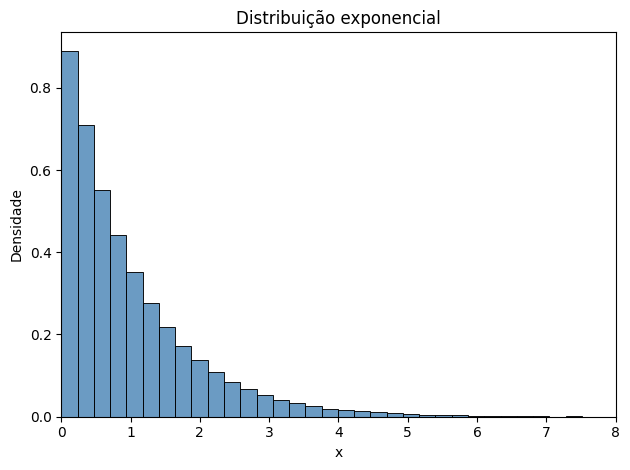

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

dados = np.random.exponential(scale=1, size=100000)

sns.histplot(
    dados,
    bins=50,
    stat='density',
    color='steelblue',
    edgecolor='black',
    alpha=0.8
)

plt.title('Distribuição exponencial')
plt.xlabel('x')
plt.ylabel('Densidade')
plt.xlim(0, 8)

plt.tight_layout()
plt.show()

Observa-se uma elevada concentração de valores próximos de zero e uma longa cauda à direita. O formato é claramente diferente de uma distribuição normal, que apresentaria uma forma aproximadamente simétrica em torno da média.

Em seguida, gera-se muitas amostras independentes e calcula-se suas médias para diferentes tamanhos amostrais. Para a simulação da distribuição exponencial, adota-se o parâmetro de taxa $\lambda = 1$. A partir deste parâmetro, definem-se as propriedades teóricas da população:
* **Média ($\mu$):** $1 / \lambda = 1.0$
* **Desvio padrão ($\sigma$):** $1 / \lambda = 1.0$
* **Erro padrão teórico para o tamanho de amostra $n$:** $\sigma_{\bar{x}} = \frac{1}{\sqrt{n}}$


[Exponencial] n=1 | Média teórica: 1.00 vs simulada: 0.9775
[Exponencial] n=1 | Erro padrão teórico: 1.0000 vs simulado: 0.9744

[Exponencial] n=5 | Média teórica: 1.00 vs simulada: 1.0019
[Exponencial] n=5 | Erro padrão teórico: 0.4472 vs simulado: 0.4480

[Exponencial] n=10 | Média teórica: 1.00 vs simulada: 1.0006
[Exponencial] n=10 | Erro padrão teórico: 0.3162 vs simulado: 0.3145

[Exponencial] n=30 | Média teórica: 1.00 vs simulada: 0.9999
[Exponencial] n=30 | Erro padrão teórico: 0.1826 vs simulado: 0.1822

[Exponencial] n=50 | Média teórica: 1.00 vs simulada: 1.0018
[Exponencial] n=50 | Erro padrão teórico: 0.1414 vs simulado: 0.1423

[Exponencial] n=100 | Média teórica: 1.00 vs simulada: 0.9987
[Exponencial] n=100 | Erro padrão teórico: 0.1000 vs simulado: 0.1005

[Exponencial] n=300 | Média teórica: 1.00 vs simulada: 1.0000
[Exponencial] n=300 | Erro padrão teórico: 0.0577 vs simulado: 0.0577

[Exponencial] n=500 | Média teórica: 1.00 vs simulada: 0.9999
[Exponencial] n=500 |

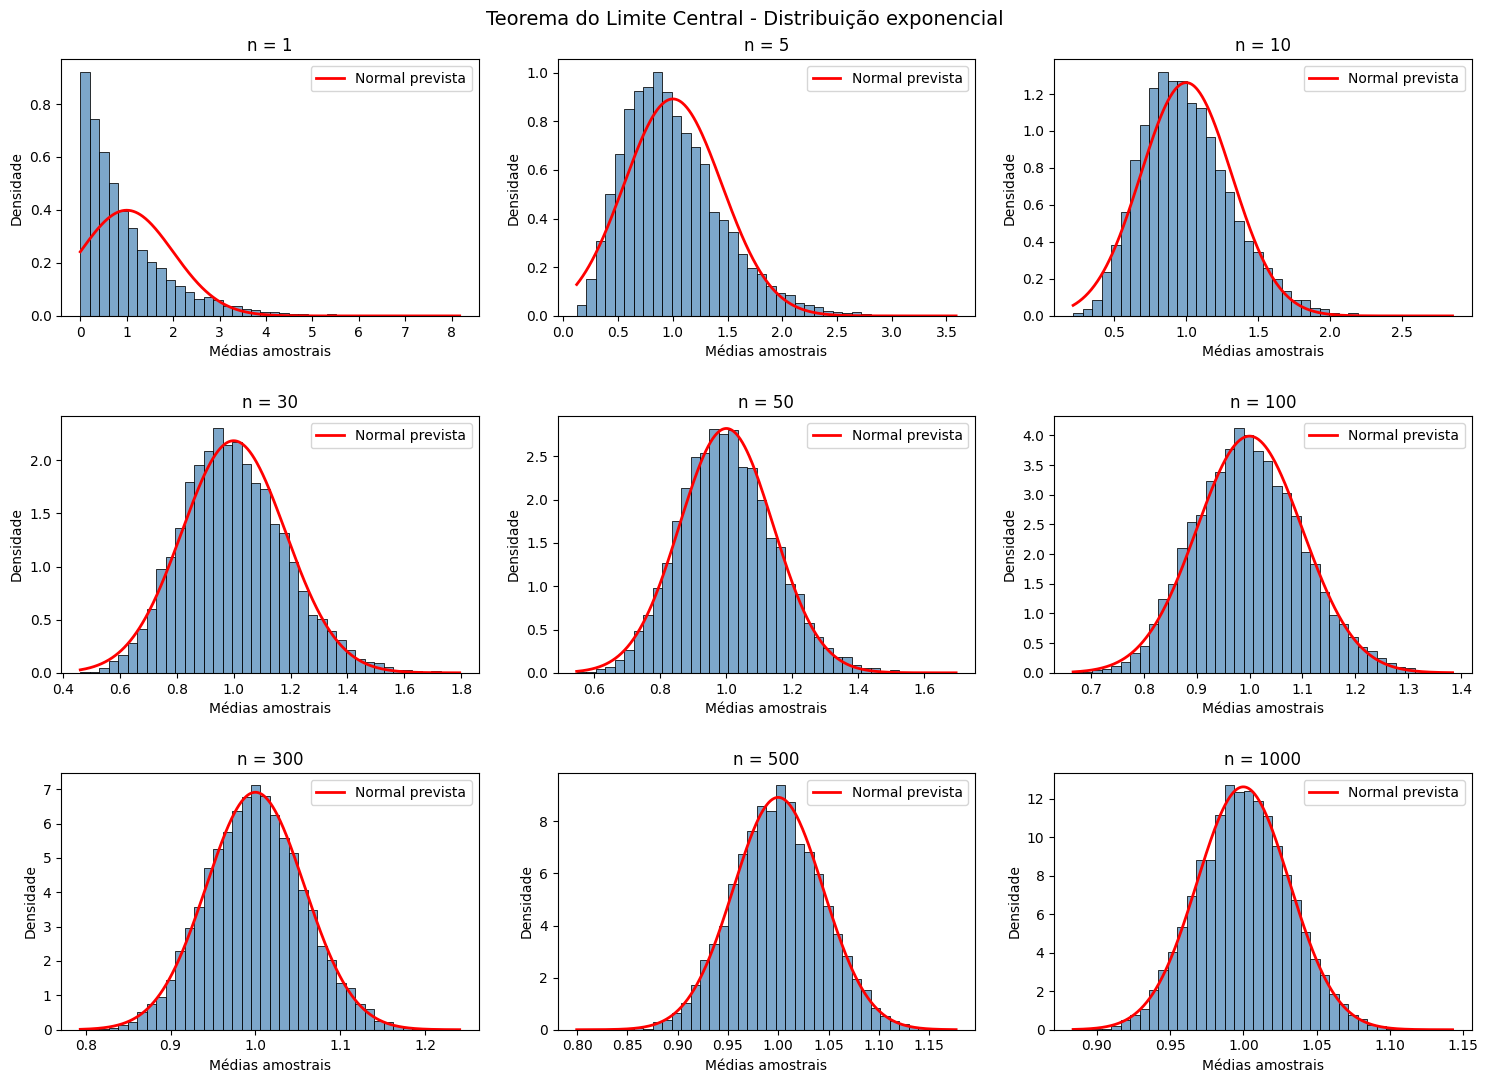

In [10]:
from scipy.stats import norm

np.random.seed(42)

scale = 1
mu = scale
sigma = scale

ns = [1, 5, 10, 30, 50, 100, 300, 500, 1000]
n_sim = 10000

fig, axes = plt.subplots(3, 3, figsize=(15, 11))

for ax, n in zip(axes.flat, ns):

    medias = [
        np.mean(np.random.exponential(scale=scale, size=n))
        for _ in range(n_sim)
    ]

    mu_teorico = 1.0
    sigma_teorico = 1.0
    erro_teorico = sigma_teorico / np.sqrt(n)
    
    media_simulada = np.mean(medias)
    erro_simulado = np.std(medias)
    
    print(f"[Exponencial] n={n} | Média teórica: {mu_teorico:.2f} vs simulada: {media_simulada:.4f}")
    print(f"[Exponencial] n={n} | Erro padrão teórico: {erro_teorico:.4f} vs simulado: {erro_simulado:.4f}\n")

    sns.histplot(
        medias,
        bins=40,
        stat='density',
        color='steelblue',
        alpha=0.7,
        ax=ax
    )

    x = np.linspace(min(medias), max(medias), 500)
    y = norm.pdf(x, loc=mu, scale=sigma/np.sqrt(n))

    ax.plot(
        x,
        y,
        color='red',
        linewidth=2,
        label='Normal prevista'
    )

    ax.set_title(f'n = {n}', fontsize=12)
    ax.legend()

    ax.set_xlabel('Médias amostrais', fontsize=10)
    ax.set_ylabel('Densidade', fontsize=10)

plt.suptitle(
    'Teorema do Limite Central - Distribuição exponencial',
    fontsize=14,
    y=0.98
)

plt.tight_layout(h_pad=2.5, w_pad=2.0)
plt.show()

Percebe-se que, para valores pequenos de $n$, a distribuição mantém características marcantes da distribuição exponencial original, especialmente a assimetria à direita. Contudo, à medida que mais observações são incorporadas ao cálculo de cada média, essa assimetria torna-se menos pronunciada e a distribuição passa a apresentar um formato cada vez mais próximo de uma curva em sino.

A mudança é mais perceptível ao comparar os casos $n=1$, $n=30$ e $n=100$. Enquanto para $n=1$ a discrepância em relação à curva normal é evidente, em $n=30$ já se observa uma aproximação bastante satisfatória, e para $n=100$ a concordância entre o histograma e a distribuição normal teórica torna-se notável. Além da alteração de forma, observa-se uma redução contínua da dispersão das médias amostrais, que passam a se concentrar cada vez mais ao redor da média populacional.

Para valores ainda maiores de $n$, como $300$, $500$ e $1000$, a principal mudança observada não é mais na forma da distribuição, mas em sua largura. Nesses casos, a distribuição já possui comportamento normal e o aumento do tamanho amostral contribui principalmente para reduzir a variabilidade das médias, tornando-as progressivamente mais concentradas em torno do valor esperado. Esses resultados mostram que, mesmo partindo de uma distribuição claramente não normal, as médias amostrais convergem rapidamente para o comportamento normal.

A próxima distribuição a ser analisada será a uniforme.

<h3>2. Distribuição uniforme</h3>

A distribuição uniforme representa um caso em que todos os valores dentro de um determinado intervalo possuem a mesma probabilidade de ocorrência. Diferentemente da distribuição exponencial, ela não apresenta assimetria, mas também não possui o formato característico de sino associado à distribuição normal. Sua forma é aproximadamente retangular, tornando-a um exemplo interessante para avaliar a convergência prevista pelo Teorema do Limite Central.

Inicialmente, analisa-se a distribuição original dos dados.

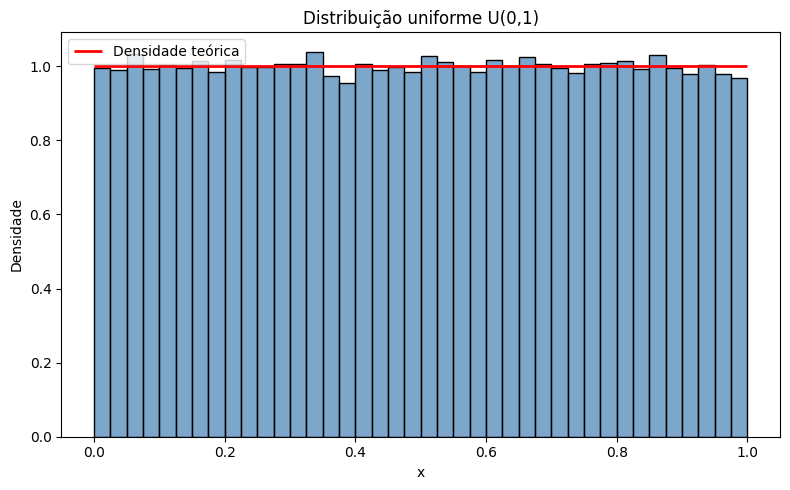

In [3]:
np.random.seed(42)

dados = np.random.uniform(0, 1, 100000)

plt.figure(figsize=(8,5))

sns.histplot(
    dados,
    bins=40,
    stat='density',
    color='steelblue',
    edgecolor='black',
    alpha=0.7
)

plt.hlines(
    y=1,
    xmin=0,
    xmax=1,
    color='red',
    lw=2,
    label='Densidade teórica'
)

plt.title('Distribuição uniforme U(0,1)')
plt.xlabel('x')
plt.ylabel('Densidade')
plt.legend()

plt.tight_layout()
plt.show()

Percebe-se que todos os valores do intervalo possuem a mesma probabilidade de ocorrência. Observa-se uma boa concordância entre o histograma obtido por simulação e a densidade teórica constante, evidenciando a ausência de picos, caudas pronunciadas ou assimetrias na distribuição original.

Em seguida, gera-se muitas amostras independentes e calcula-se suas médias para diferentes tamanhos amostrais.

[Uniforme] n=1 | Média teórica: 5.00 vs simulada: 4.9416
[Uniforme] n=1 | Erro padrão teórico: 2.8868 vs simulado: 2.8762

[Uniforme] n=5 | Média teórica: 5.00 vs simulada: 5.0066
[Uniforme] n=5 | Erro padrão teórico: 1.2910 vs simulado: 1.2929

[Uniforme] n=10 | Média teórica: 5.00 vs simulada: 5.0056
[Uniforme] n=10 | Erro padrão teórico: 0.9129 vs simulado: 0.9121

[Uniforme] n=30 | Média teórica: 5.00 vs simulada: 5.0017
[Uniforme] n=30 | Erro padrão teórico: 0.5270 vs simulado: 0.5257

[Uniforme] n=50 | Média teórica: 5.00 vs simulada: 5.0036
[Uniforme] n=50 | Erro padrão teórico: 0.4082 vs simulado: 0.4096

[Uniforme] n=100 | Média teórica: 5.00 vs simulada: 4.9948
[Uniforme] n=100 | Erro padrão teórico: 0.2887 vs simulado: 0.2894

[Uniforme] n=300 | Média teórica: 5.00 vs simulada: 5.0003
[Uniforme] n=300 | Erro padrão teórico: 0.1667 vs simulado: 0.1657

[Uniforme] n=500 | Média teórica: 5.00 vs simulada: 5.0002
[Uniforme] n=500 | Erro padrão teórico: 0.1291 vs simulado: 0.1287

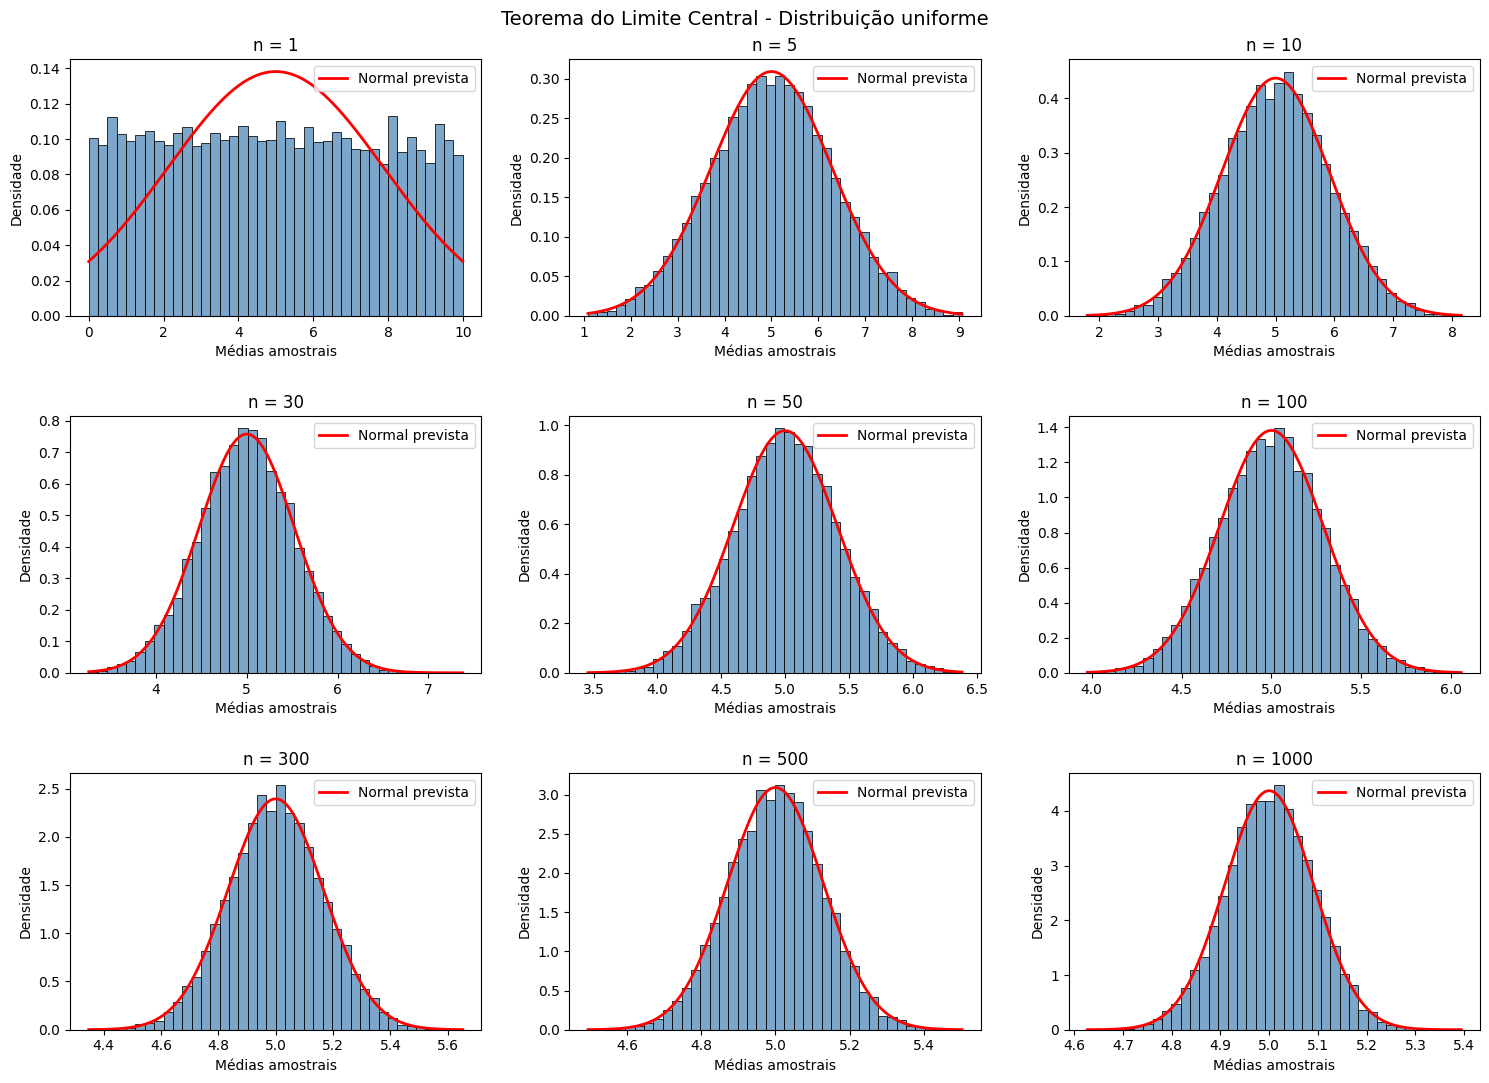

In [4]:
np.random.seed(42)
a = 0
b = 10
mu = (a + b) / 2
sigma = (b - a) / np.sqrt(12)

ns = [1, 5, 10, 30, 50, 100, 300, 500, 1000]
n_sim = 10000
fig, axes = plt.subplots(3, 3, figsize=(15, 11))

for ax, n in zip(axes.flat, ns):
    medias = [np.mean(np.random.uniform(a, b, size=n)) for _ in range(n_sim)]
    
    mu_teorico = 5.0
    sigma_teorico = np.sqrt(100 / 12) 
    erro_teorico = sigma_teorico / np.sqrt(n)
    media_simulada = np.mean(medias)
    erro_simulado = np.std(medias)
    
    print(f"[Uniforme] n={n} | Média teórica: {mu_teorico:.2f} vs simulada: {media_simulada:.4f}")
    print(f"[Uniforme] n={n} | Erro padrão teórico: {erro_teorico:.4f} vs simulado: {erro_simulado:.4f}\n")
    
    sns.histplot(medias, bins=40, stat='density', color='steelblue', alpha=0.7, ax=ax)
    x = np.linspace(min(medias), max(medias), 500)
    y = norm.pdf(x, loc=mu, scale=sigma/np.sqrt(n))
    ax.plot(x, y, color='red', linewidth=2, label='Normal prevista')
    ax.set_title(f'n = {n}', fontsize=12)
    ax.legend()
    ax.set_xlabel('Médias amostrais', fontsize=10)
    ax.set_ylabel('Densidade', fontsize=10)

plt.suptitle('Teorema do Limite Central - Distribuição uniforme', fontsize=14, y=0.98)
plt.tight_layout(h_pad=2.5, w_pad=2.0)
plt.show()

Diferentemente do caso exponencial, a distribuição original já apresenta simetria em torno da média populacional, embora possua um formato retangular bastante distinto de uma distribuição normal. Conforme o tamanho amostral aumenta, observa-se o surgimento gradual de uma curva em sino centrada em $\mu = 0.5$, acompanhada de uma redução progressiva da dispersão das médias.

A aproximação à distribuição normal ocorre de forma até que rápida. Já para $n=5$ e $n=10$, a distribuição das médias apresenta formato bastante próximo ao previsto teoricamente, e essa concordância torna-se ainda mais evidente para $n=30$ e $n=100$. Além da mudança de forma, nota-se que as médias amostrais passam a se concentrar cada vez mais em torno do valor esperado.

Para valores maiores de $n$, como $300$, $500$ e $1000$, a distribuição já exibe comportamento normal, de modo que o principal efeito do aumento amostral torna-se a diminuição da variabilidade. Nesse regime, observa-se uma concentração crescente das médias em torno da média populacional, evidenciando o comportamento normal.

A próxima e última distribuição a ser analisada será a bimodal.

<h3>3. Bimodal</h3>

Como terceiro caso de estudo, considera-se uma distribuição bimodal. Diferentemente das distribuições exponencial e uniforme, a distribuição bimodal apresenta dois máximos locais, indicando a existência de duas regiões de maior concentração de dados. 

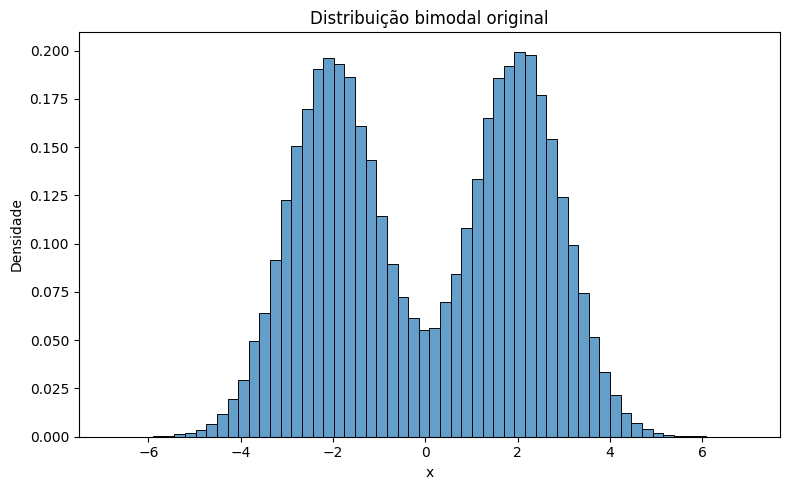

In [5]:
rng = np.random.default_rng(42)

N = 100_000

componentes = rng.choice([0, 1], size=N)

dados = np.where(
    componentes == 0,
    rng.normal(-2, 1, N),
    rng.normal(2, 1, N)
)

plt.figure(figsize=(8, 5))

sns.histplot(
    dados,
    bins=60,
    stat="density",
    edgecolor="black",
    alpha=0.7
)

plt.title("Distribuição bimodal original")
plt.xlabel("x")
plt.ylabel("Densidade")
plt.tight_layout()
plt.show()

Observam-se dois picos bem definidos, aproximadamente centrados em $-2$ e $2$, evidenciando a presença de duas regiões distintas de concentração de dados. 

Em seguida, gera-se muitas amostras independentes e calcula-se suas médias para diferentes tamanhos amostrais.

[Bimodal] n=1 | Média teórica: 0.00 vs simulada: -0.0028
[Bimodal] n=1 | Erro padrão teórico: 2.2361 vs simulado: 2.2499

[Bimodal] n=5 | Média teórica: 0.00 vs simulada: 0.0013
[Bimodal] n=5 | Erro padrão teórico: 1.0000 vs simulado: 1.0010

[Bimodal] n=10 | Média teórica: 0.00 vs simulada: 0.0035
[Bimodal] n=10 | Erro padrão teórico: 0.7071 vs simulado: 0.7148

[Bimodal] n=30 | Média teórica: 0.00 vs simulada: 0.0005
[Bimodal] n=30 | Erro padrão teórico: 0.4082 vs simulado: 0.4092

[Bimodal] n=50 | Média teórica: 0.00 vs simulada: 0.0039
[Bimodal] n=50 | Erro padrão teórico: 0.3162 vs simulado: 0.3160

[Bimodal] n=100 | Média teórica: 0.00 vs simulada: -0.0001
[Bimodal] n=100 | Erro padrão teórico: 0.2236 vs simulado: 0.2249

[Bimodal] n=300 | Média teórica: 0.00 vs simulada: -0.0005
[Bimodal] n=300 | Erro padrão teórico: 0.1291 vs simulado: 0.1306

[Bimodal] n=500 | Média teórica: 0.00 vs simulada: -0.0005
[Bimodal] n=500 | Erro padrão teórico: 0.1000 vs simulado: 0.1003

[Bimodal] 

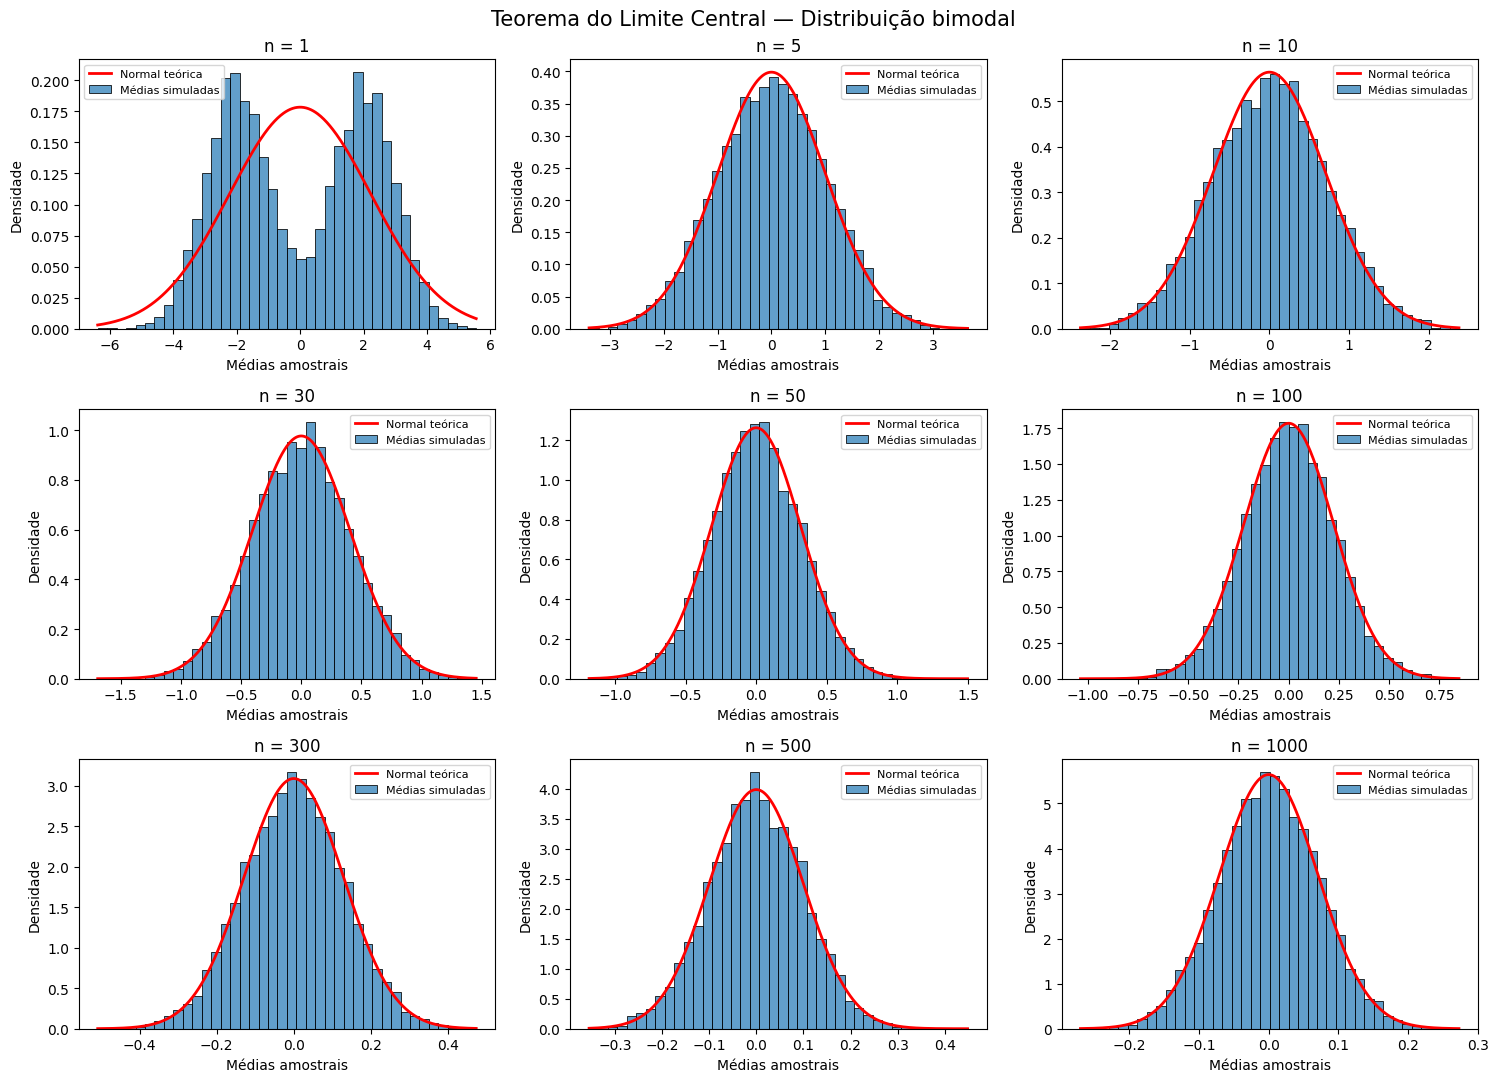

In [11]:
rng = np.random.default_rng(42)

mu_comp1, sigma_comp1 = -2, 1
mu_comp2, sigma_comp2 = 2, 1

mu_pop = 0.0 
sigma_pop = np.sqrt(0.5 * (sigma_comp1**2 + mu_comp1**2) + 0.5 * (sigma_comp2**2 + mu_comp2**2) - mu_pop**2) 

ns = [1, 5, 10, 30, 50, 100, 300, 500, 1000]
n_sim = 10000
fig, axes = plt.subplots(3, 3, figsize=(15, 11))

for ax, n in zip(axes.flat, ns):
    componentes = rng.choice([0, 1], size=(n_sim, n))
    valores = np.where(componentes == 0, rng.normal(mu_comp1, sigma_comp1, size=(n_sim, n)), rng.normal(mu_comp2, sigma_comp2, size=(n_sim, n)))
    medias = valores.mean(axis=1)
    
    erro_teorico = sigma_pop / np.sqrt(n)
    media_simulada = np.mean(medias)
    erro_simulado = np.std(medias)
    
    print(f"[Bimodal] n={n} | Média teórica: {mu_pop:.2f} vs simulada: {media_simulada:.4f}")
    print(f"[Bimodal] n={n} | Erro padrão teórico: {erro_teorico:.4f} vs simulado: {erro_simulado:.4f}\n")
    
    sns.histplot(medias, bins=40, stat="density", alpha=0.7, ax=ax, label="Médias simuladas")

    x = np.linspace(min(medias), max(medias), 500)
    y = norm.pdf(x, loc=mu_pop, scale=erro_teorico)
    ax.plot(x, y, color="red", linewidth=2, label="Normal teórica")
    
    ax.set_title(f"n = {n}")
    ax.set_xlabel("Médias amostrais")
    ax.set_ylabel("Densidade")
    ax.legend(fontsize=8)

fig.suptitle("Teorema do Limite Central — Distribuição bimodal", fontsize=15)
plt.tight_layout()
plt.show()

Para $n = 1$, os dois picos característicos da distribuição original permanecem evidentes, indicando que uma única observação não é suficiente para produzir uma distribuição aproximadamente normal das médias. 
À medida que o tamanho amostral aumenta, a influência dos dois componentes torna-se progressivamente menos pronunciada. Para valores intermediários de $n$, a distribuição das médias passa a apresentar uma forma mais próxima de uma curva em sino, centrada na média populacional, igual a zero. Para tamanhos amostrais maiores, a aproximação à normal teórica torna-se mais evidente. Portanto, mesmo partindo de uma população bimodal, a distribuição das médias amostrais tende a se aproximar da normal.

<h3>4. Análise de resultados</h3>

Ao analisar os outputs numéricos gerados pelos experimentos, valida-se matematicamente a convergência que os gráficos sugerem visualmente. 

Nas três distribuições com momentos finitos (exponencial, uniforme e bimodal), a **média simulada** das amostras estabiliza-se e aproxima-se da **média teórica** populacional com alta precisão a partir de tamanhos amostrais pequenos ($n \ge 30$). Isso confirma a propriedade estatística de que a média amostral funciona como um estimador não viesado do parâmetro populacional.

Além disso, à medida que o valor de $n$ aumenta de $1$ para $1000$, a dispersão (desvio padrão das médias simuladas) cai de maneira proporcional à fórmula teórica $\sigma / \sqrt{n}$. Por exemplo:

* Na **exponencial**, o erro padrão cai de $1.0000$ ($n=1$) para $0.0316$ ($n=1000$).
* Na **uniforme (U[0,10])**, ele reduz de $2.8868$ para $0.0913$.
* Na **bimodal**, reduz-se de $2.2361$ para $0.0705$.

Esses dados numéricos provam empiricamente o ganho de precisão: quanto maior o tamanho do experimento ou da coleta de dados, menor será a variabilidade da estimativa, seguindo a lei do inverso da raiz quadrada de $n$.

Em suma, os testes empíricos aplicados às distribuições exponencial, uniforme e bimodal confirmam o comportamento normal previsto pelo Teorema do Limite Central. Embora os dados populacionais originais possuam naturezas geométricas completamente distintas (uma com assimetria à direita, outra retangular e plana, e a última dividida em dois picos), todas convergiram à mesma lei matemática. Conforme o tamanho amostral se expande, os traços particulares e as irregularidades de cada distribuição de origem são atenuados, dando lugar à clássica simetria da curva de sino. Esses experimentos confirmam a validade do $\text{TLC}$.

<h3>5. Distribuição de Cauchy</h3>

Diferentemente das anteriores, a distribuição de Cauchy possui caudas pesadas, o que significa que valores discrepantes (outliers) ocorrem com uma frequência muito maior do que em distribuições tradicionais.

Inicialmente, visualiza-se a distribuição original.

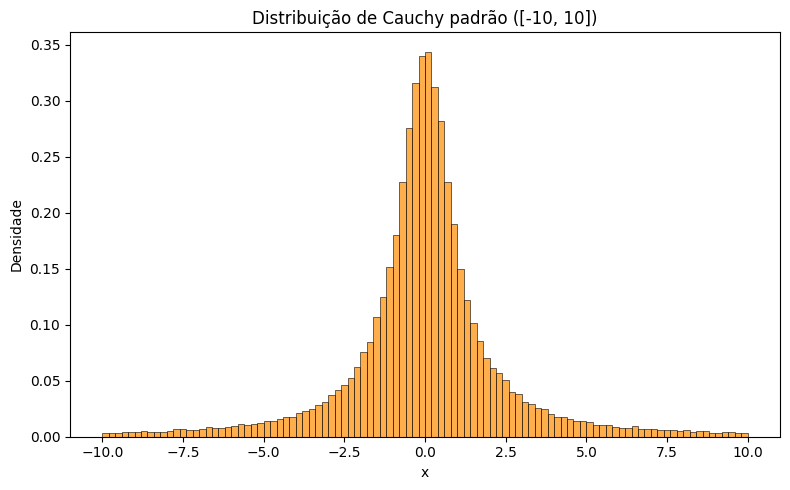

In [7]:
rng = np.random.default_rng(42)
dados_cauchy = rng.standard_cauchy(100000)

dados_filtrados = dados_cauchy[(dados_cauchy > -10) & (dados_cauchy < 10)]

plt.figure(figsize=(8, 5))
sns.histplot(dados_filtrados, bins=100, stat='density', color='darkorange', alpha=0.7)
plt.title('Distribuição de Cauchy padrão ([-10, 10])')
plt.xlabel('x')
plt.ylabel('Densidade')
plt.tight_layout()
plt.show()


O histograma revela um pico central muito agudo e caudas longas. A seguir, repete-se o procedimento de gerar médias amostrais para diferentes tamanhos de $n$.

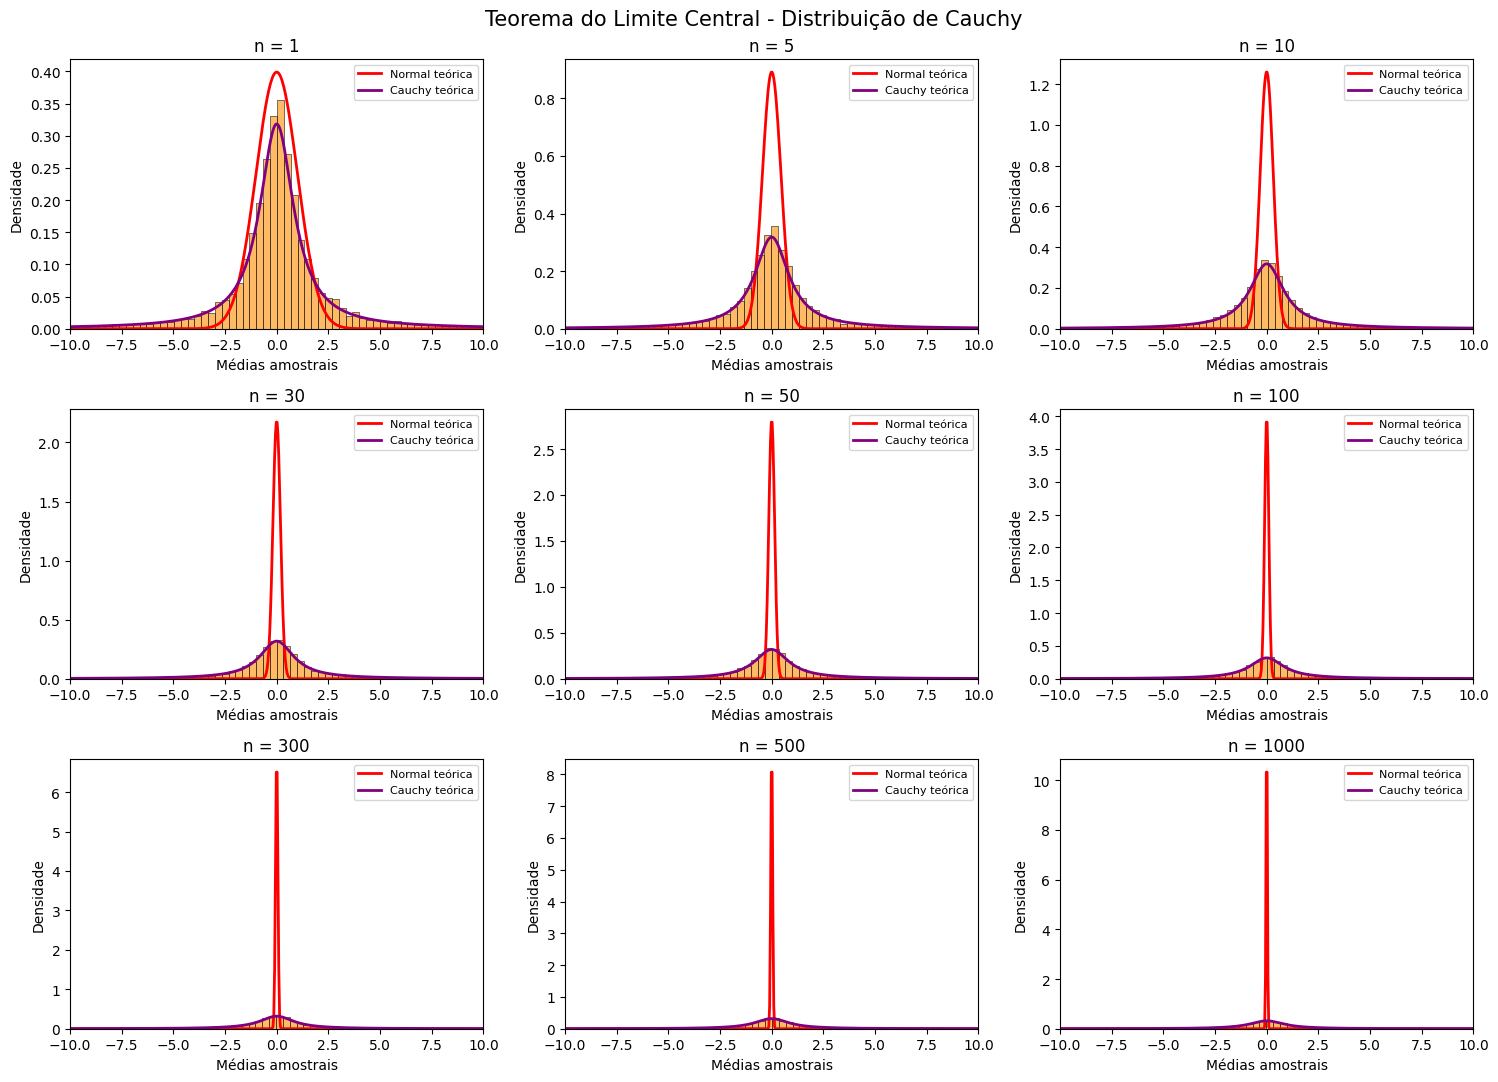

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, cauchy

rng = np.random.default_rng(seed=42)

ns = [1, 5, 10, 30, 50, 100, 300, 500, 1000]
n_sim = 10000

fig, axes = plt.subplots(3, 3, figsize=(15, 11))

for ax, n in zip(axes.flat, ns):
    amostras = rng.standard_cauchy(size=(n_sim, n))
    medias = amostras.mean(axis=1)

    medias_plot = medias[(medias > -10) & (medias < 10)]

    sns.histplot(medias_plot, bins=60, stat='density', color='darkorange', alpha=0.6, ax=ax)

    x_plot = np.linspace(-10, 10, 500)

    mu_pop = 0
    erro_teorico = 1 / np.sqrt(n) 
    
    y_normal = norm.pdf(x_plot, loc=mu_pop, scale=erro_teorico)
    ax.plot(x_plot, y_normal, color="red", linewidth=2, label="Normal teórica")

    y_cauchy = cauchy.pdf(x_plot)
    ax.plot(x_plot, y_cauchy, color='purple', linewidth=2, label='Cauchy teórica')

    ax.set_title(f'n = {n}')
    ax.set_xlabel('Médias amostrais')
    ax.set_ylabel('Densidade')
    ax.set_xlim(-10, 10)
    ax.legend(fontsize=8)

fig.suptitle("Teorema do Limite Central - Distribuição de Cauchy", fontsize=15)
plt.tight_layout()
plt.show()

Diferentemente dos três cenários anteriores, **a distribuição das médias amostrais da Cauchy não converge para uma curva normal**. Como observado nos gráficos, mesmo para amostras grandes como $n = 1000$, o histograma das médias mantém exatamente o mesmo formato pontiagudo e com caudas pesadas da distribuição original de Cauchy. 

O Teorema do Limite Central não funciona neste caso porque ele exige estritamente que a distribuição de origem possua **média e variância finitas**. A distribuição de Cauchy falha nessa premissa: matematicamente, suas caudas são tão pesadas que a integral que define sua média não converge (a média é indefinida) e sua variância é infinita. Uma propriedade matemática notável da Cauchy é que a média de $n$ variáveis independentes de Cauchy segue exatamente a mesma distribuição de Cauchy original. Portanto, o aumento do tamanho amostral não reduz a dispersão e nem altera a forma geométrica da distribuição das médias.

<h3>6. Aplicações do $\text{TLC}$</h3>

A convergência garantida pelo $\text{TLC}$ não possui apenas valor teórico; ela viabiliza a existência da estatística moderna em diversas áreas, como:

* **Pesquisas de opinião e eleitorais:** permite calcular margens de erro e intervalos de confiança para proporções políticas ou de consumo. Graças ao teorema, sabe-se que a distribuição das proporções amostrais será normal, independentemente de como as opiniões individuais estão distribuídas na população.
  
* **Controle de qualidade industrial:** em linhas de produção, engenheiros coletam pequenas amostras de peças ao longo do dia e calculam suas médias (por exemplo, diâmetro ou peso). O $\text{TLC}$ permite construir os chamados "Gráficos de controle" usando os limites de três desvios padrões da normal para detectar anomalias no processo produtivo.

* **Finanças e gerenciamento de risco:** no mercado financeiro, carteiras de investimento lidam com a soma de retornos de centenas de ativos diferentes. O teorema justifica modelar o risco agregado de grandes portfólios por meio de distribuições normais (como no cálculo do *Value at Risk* - VaR).

* **Ciência de dados e testes A/B:** na validação de novos recursos em softwares ou sites, utiliza-se testes de hipóteses (como o Teste t de Student) para comparar as médias de engajamento entre dois grupos. O $\text{TLC}$ garante que esses testes estatísticos sejam válidos para grandes volumes de usuários, mesmo que o engajamento original seja uma variável estritamente assimétrica.


<h2>Conclusão</h2>

Ao analisar as distribuições exponencial (assimétrica), uniforme (plana) e bimodal (com dois picos de frequência), observou-se o mesmo fenômeno em todas elas: à medida que o tamanho da amostra ($n$) aumentou, a distribuição das médias amostrais abandonou suas formas originais e convergiu perfeitamente para uma distribuição normal. Além disso, confirmou-se visual e estatisticamente que a variabilidade dessas médias reduz de forma previsível na razão de $\sigma / \sqrt{n}$. Essa previsibilidade matemática justifica o $\text{TLC}$ como ferramenta, viabilizando uma série de aplicações em diversas áreas.

Por fim, a comparação com a distribuição de Cauchy serviu como um importante contraexemplo. Ele evidenciou que o $\text{TLC}$ não é uma regra universal. Como a distribuição de Cauchy não possui média definida e sua variância é infinita, ela viola as condições de contorno do teorema, mantendo sua forma inalterada e provando que a finitude da variância é necessária para a convergência à normalidade.

<h2>Referências bibliográficas</h2>

$[1]$ WATKINS, Joseph C. **Topic 11: The Central Limit Theorem**. In: WATKINS, Joseph C. An Introduction to the Science of Statistics: From Theory to Implementation. Preliminary Edition. Tucson: University of Arizona, 2021. p. 167-182. Disponível em: <https://archive.math.arizona.edu/jwatkins/K_clt.pdf>. Acesso em: 21 out. 2026.

<h2>Interação com a IA</h2>

A inteligência artificial generativa foi utilizada ao longo do projeto como ferramenta de apoio na parte da programação, resolvendo dúvidas de sintaxe e realizando correções de erros de código (*debugging*). Além disso, também auxiliou no levantamento de aplicações práticas do $\text{TLC}$.